In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv('train.csv')

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Saving train.csv to train.csv
Dataset loaded successfully!
Shape: (891, 12)


In [ ]:
df.head(10)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [ ]:
print("Attribute Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)


Attribute Names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Data Types:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object


In [ ]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
for col in ['Age', 'Fare']:
    print("\n---", col, "---")

    print("Minimum:", df[col].min())
    print("Maximum:", df[col].max())
    print("Range:", df[col].max() - df[col].min())

    print("Q1:", df[col].quantile(0.25))
    print("Median:", df[col].quantile(0.50))
    print("Q3:", df[col].quantile(0.75))

    print("10th Percentile:", df[col].quantile(0.10))
    print("90th Percentile:", df[col].quantile(0.90))


--- Age ---
Minimum: 0.42
Maximum: 80.0
Range: 79.58
Q1: 20.125
Median: 28.0
Q3: 38.0
10th Percentile: 14.0
90th Percentile: 50.0

--- Fare ---
Minimum: 0.0
Maximum: 512.3292
Range: 512.3292
Q1: 7.9104
Median: 14.4542
Q3: 31.0
10th Percentile: 7.55
90th Percentile: 77.9583


In [ ]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [ ]:
# Fill Age with mean
df['Age'] = df['Age'].fillna(df['Age'].mean())

# Fill Embarked with mode
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

# Cabin has many missing values, so use a placeholder
df['Cabin'] = df['Cabin'].fillna('Unknown')

print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64


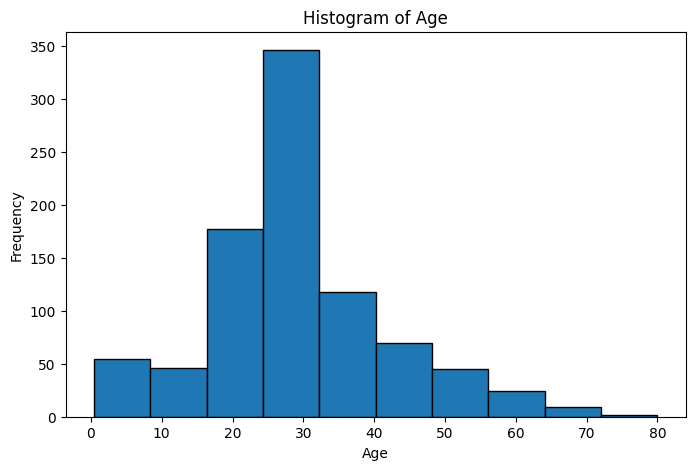

In [ ]:
plt.figure(figsize=(8,5))

plt.hist(df['Age'], bins=10, edgecolor='black')

plt.title('Histogram of Age')
plt.xlabel('Age')
plt.ylabel('Frequency')

plt.show()

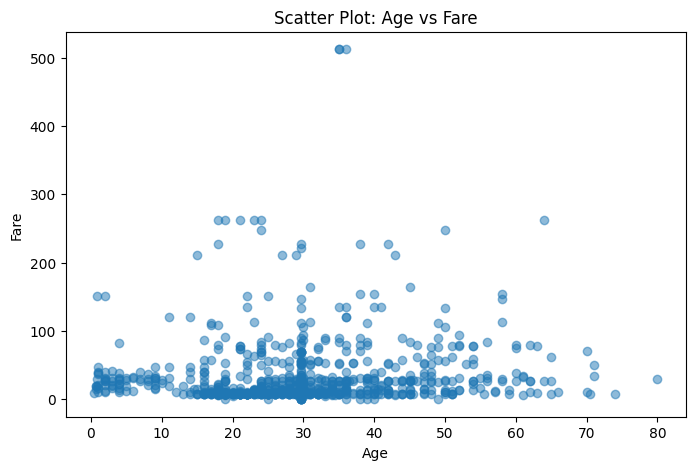

In [ ]:
plt.figure(figsize=(8,5))

plt.scatter(df['Age'], df['Fare'], alpha=0.5)

plt.title('Scatter Plot: Age vs Fare')
plt.xlabel('Age')
plt.ylabel('Fare')

plt.show()

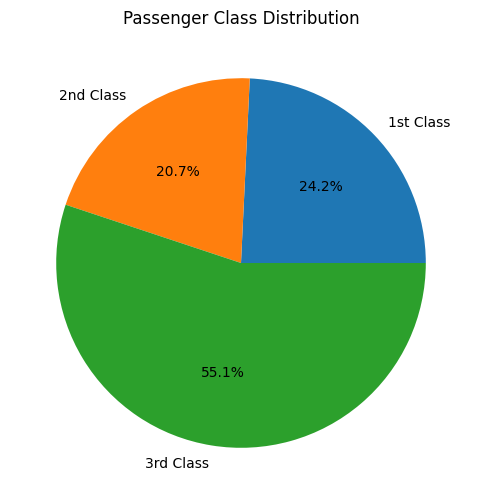

In [ ]:
class_counts = df['Pclass'].value_counts().sort_index()

plt.figure(figsize=(6,6))

plt.pie(
    class_counts,
    labels=['1st Class', '2nd Class', '3rd Class'],
    autopct='%1.1f%%'
)

plt.title('Passenger Class Distribution')

plt.show()

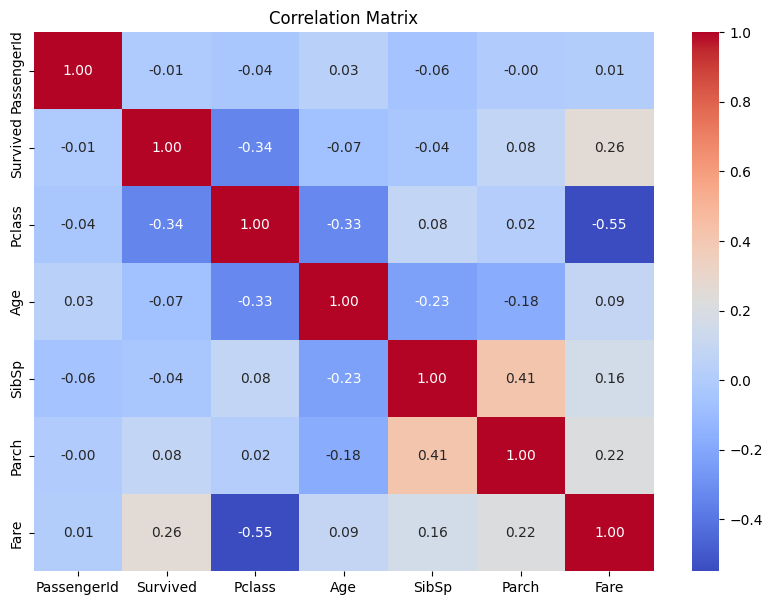

In [ ]:
numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()

plt.figure(figsize=(10,7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix')

plt.show()

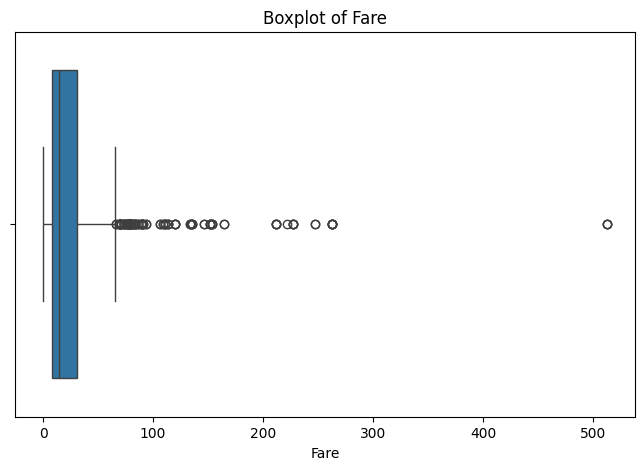

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(x=df['Fare'])

plt.title('Boxplot of Fare')
plt.xlabel('Fare')

plt.show()

In [ ]:
Q1 = df['Fare'].quantile(0.25)
Q3 = df['Fare'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df['Fare'] < lower_limit) |
    (df['Fare'] > upper_limit)
]

print("Q1 =", Q1)
print("Q3 =", Q3)
print("IQR =", IQR)
print("Lower Limit =", lower_limit)
print("Upper Limit =", upper_limit)

print("\nNumber of Outliers:", len(outliers))
print("\nOutlier Values:")
print(outliers['Fare'].values)

Q1 = 7.9104
Q3 = 31.0
IQR = 23.0896
Lower Limit = -26.724
Upper Limit = 65.6344

Number of Outliers: 116

Outlier Values:
[ 71.2833 263.     146.5208  82.1708  76.7292  80.      83.475   73.5
 263.      77.2875 247.5208  73.5     77.2875  79.2     66.6     69.55
  69.55   146.5208  69.55   113.275   76.2917  90.      83.475   90.
  79.2     86.5    512.3292  79.65   153.4625 135.6333  77.9583  78.85
  91.0792 151.55   247.5208 151.55   110.8833 108.9     83.1583 262.375
 164.8667 134.5     69.55   135.6333 153.4625 133.65    66.6    134.5
 263.      75.25    69.3    135.6333  82.1708 211.5    227.525   73.5
 120.     113.275   90.     120.     263.      81.8583  89.1042  91.0792
  90.      78.2667 151.55    86.5    108.9     93.5    221.7792 106.425
  71.     106.425  110.8833 227.525   79.65   110.8833  79.65    79.2
  78.2667 153.4625  77.9583  69.3     76.7292  73.5    113.275  133.65
  73.5    512.3292  76.7292 211.3375 110.8833 227.525  151.55   227.525
 211.3375 512.3292  78.85  

In [ ]:
mean_fare = df['Fare'].mean()

df.loc[
    (df['Fare'] < lower_limit) |
    (df['Fare'] > upper_limit),
    'Fare'
] = mean_fare

print("Outliers replaced with mean.")
print("Mean Fare:", mean_fare)

Outliers replaced with mean.
Mean Fare: 32.204207968574636


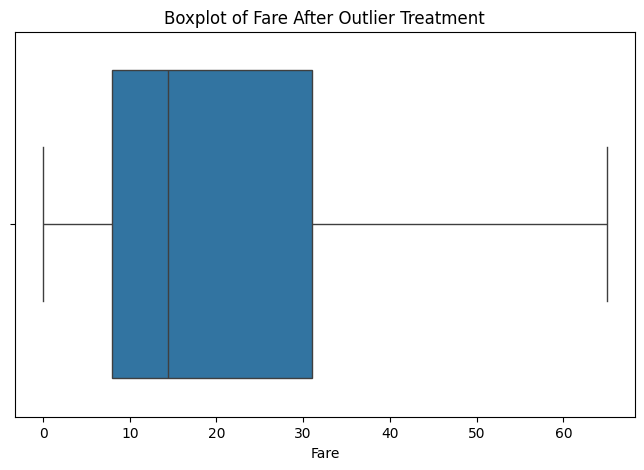

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(x=df['Fare'])

plt.title('Boxplot of Fare After Outlier Treatment')
plt.xlabel('Fare')

plt.show()

In [ ]:
print("Final Dataset:")
print(df.head(10))

print("\nMissing Values:")
print(df.isnull().sum())

Final Dataset:
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   
5            6         0       3   
6            7         0       1   
7            8         0       3   
8            9         1       3   
9           10         1       2   

                                                Name     Sex        Age  \
0                            Braund, Mr. Owen Harris    male  22.000000   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.000000   
2                             Heikkinen, Miss. Laina  female  26.000000   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.000000   
4                           Allen, Mr. William Henry    male  35.000000   
5                                   Moran, Mr. James    male  29.699118   
6                            McCarthy, Mr. Timothy J    male  5